# 电商用户行为与转化分析

## 1. 分析目标

本次分析使用 2019 年 10 月电商用户行为数据，主要回答以下问题：

1. 用户从浏览、加购到购买的转化情况如何？
2. 用户级漏斗和会话级漏斗有什么区别？
3. 严格按照行为发生顺序计算后，转化率是否发生变化？
4. 哪些时间段、品类和价格区间具有更高的购买转化表现？
5. 哪些用户群体具有较高的购买意向？

分析结果将用于识别主要流失环节，并为后续购买意向预测和运营策略设计提供依据。

## 2. 指标口径

### 事件级指标

每一行数据代表一次行为事件。事件数用于衡量浏览、加购和购买行为发生的频次，但不能直接代表用户转化率。

### 用户级漏斗

以 `user_id` 为统计单位：

- 浏览用户数：至少发生过一次浏览行为的用户数；
- 加购用户数：至少发生过一次加购行为的用户数；
- 购买用户数：至少发生过一次购买行为的用户数。

用户级漏斗反映整个月内有多少用户到达过各行为阶段，但普通用户漏斗不要求行为发生在同一会话，也不要求严格遵循浏览、加购、购买的时间顺序。

### 会话级漏斗

以 `user_session` 为统计单位：

- 浏览会话数：包含浏览行为的会话数；
- 加购会话数：包含加购行为的会话数；
- 购买会话数：包含购买行为的会话数。

会话级漏斗更接近一次访问过程，但普通会话漏斗仍不保证行为严格按照浏览、加购、购买的顺序发生。

### 严格顺序漏斗

在同一用户或同一会话中，只有后续行为发生时间晚于前一阶段时，才计入下一阶段：

```text
浏览时间 ≤ 加购时间 ≤ 购买时间

In [1]:
#连接清洗后的数据
import sys
from pathlib import Path

import duckdb
import pandas as pd

print("Python 路径：", sys.executable)
print("DuckDB 版本：", duckdb.__version__)

Python 路径： C:\Users\29443\Documents\实习\ecommerce-conversion\.venv\Scripts\python.exe
DuckDB 版本： 1.5.5


In [2]:
clean_path = Path(
    "../data/processed/events_2019_10_clean.parquet"
).resolve()

print("数据路径：", clean_path)
print("文件存在：", clean_path.exists())
print(
    "文件大小：",
    round(clean_path.stat().st_size / 1024**3, 2),
    "GB"
)

clean_sql_path = clean_path.as_posix()

数据路径： C:\Users\29443\Documents\实习\ecommerce-conversion\data\processed\events_2019_10_clean.parquet
文件存在： True
文件大小： 0.71 GB


## 3. 普通用户级转化漏斗

本节统计整个月内到达过浏览、加购和购买阶段的不同用户数，暂不要求三个行为在同一会话内发生，也不检查行为先后顺序。

In [3]:
user_funnel = duckdb.sql(f"""
    SELECT
        COUNT(DISTINCT user_id) FILTER (
            WHERE event_type = 'view'
        ) AS view_users,

        COUNT(DISTINCT user_id) FILTER (
            WHERE event_type = 'cart'
        ) AS cart_users,

        COUNT(DISTINCT user_id) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchase_users

    FROM read_parquet('{clean_sql_path}')
""").df()

user_funnel

,view_users,cart_users,purchase_users
0,3022130,337117,347118


### 用户行为集合关系

普通阶段人数不满足逐级递减关系，购买用户数高于加购用户数。因此，在计算转化率前，需要检查浏览、加购和购买用户集合之间的重叠情况。

In [4]:
#检查浏览，加购，购买三种事件有没有关联，是否在本月同时出现
user_behavior_overlap = duckdb.sql(f"""
    WITH user_flags AS (
        SELECT
            user_id,

            MAX(
                CASE WHEN event_type = 'view'
                     THEN 1 ELSE 0 END
            ) AS has_view,

            MAX(
                CASE WHEN event_type = 'cart'
                     THEN 1 ELSE 0 END
            ) AS has_cart,

            MAX(
                CASE WHEN event_type = 'purchase'
                     THEN 1 ELSE 0 END
            ) AS has_purchase

        FROM read_parquet('{clean_sql_path}')
        GROUP BY user_id
    )

    SELECT
        COUNT(*) FILTER (
            WHERE has_view = 1
              AND has_cart = 1
        ) AS view_and_cart_users,

        COUNT(*) FILTER (
            WHERE has_view = 1
              AND has_purchase = 1
        ) AS view_and_purchase_users,

        COUNT(*) FILTER (
            WHERE has_view = 1
              AND has_cart = 1
              AND has_purchase = 1
        ) AS all_three_users,

        COUNT(*) FILTER (
            WHERE has_purchase = 1
              AND has_cart = 0
        ) AS purchase_without_cart_users,

        COUNT(*) FILTER (
            WHERE has_cart = 1
              AND has_purchase = 0
        ) AS cart_without_purchase_users

    FROM user_flags
""").df()

user_behavior_overlap.T

,0
view_and_cart_users,336996
view_and_purchase_users,347056
all_three_users,202754
purchase_without_cart_users,144341
cart_without_purchase_users,134340


In [5]:
#构建用户漏斗，保证用户集合逐层包含，不保证时间顺序
view_users = int(user_funnel.loc[0, "view_users"])
view_and_cart_users = int(
    user_behavior_overlap.loc[0, "view_and_cart_users"]
)
all_three_users = int(
    user_behavior_overlap.loc[0, "all_three_users"]
)

ordinary_user_funnel = pd.DataFrame({
    "stage": [
        "view",
        "view_and_cart",
        "view_cart_purchase"
    ],
    "user_count": [
        view_users,
        view_and_cart_users,
        all_three_users
    ]
})

ordinary_user_funnel["conversion_from_view_pct"] = (
    ordinary_user_funnel["user_count"]
    / view_users
    * 100
).round(2)

ordinary_user_funnel["conversion_from_previous_pct"] = [
    100.00,
    round(view_and_cart_users / view_users * 100, 2),
    round(all_three_users / view_and_cart_users * 100, 2)
]

ordinary_user_funnel

,stage,user_count,conversion_from_view_pct,conversion_from_previous_pct
0,view,3022130,100.00,100.00
1,view_and_cart,336996,11.15,11.15
2,view_cart_purchase,202754,6.71,60.17


### 普通用户漏斗结论

- 2019 年 10 月共有 3,022,130 名浏览用户。
- 其中 336,996 名用户同时发生过浏览和加购行为，占浏览用户的 11.15%。
- 202,754 名用户同时发生过浏览、加购和购买行为，占浏览用户的 6.71%。
- 同时发生浏览和加购的用户中，60.17% 也发生过购买。

该漏斗仅根据整个月内是否出现对应行为构造，没有检查行为发生顺序，因此只能解释为月度用户行为组合漏斗，不能直接解释为严格的浏览—加购—购买转化率。

## 4. 严格顺序用户漏斗

严格顺序用户漏斗要求同一用户的加购时间不早于浏览时间，购买时间不早于符合条件的加购时间。该口径排除了行为顺序不完整和直接购买用户。

In [6]:
sequential_user_funnel = duckdb.sql(f"""
    WITH events AS (
        SELECT
            user_id,
            event_time,
            event_type
        FROM read_parquet('{clean_sql_path}')
    ),

    first_view AS (
        SELECT
            user_id,
            MIN(event_time) AS first_view_time
        FROM events
        WHERE event_type = 'view'
        GROUP BY user_id
    ),

    first_cart_after_view AS (
        SELECT
            e.user_id,
            MIN(e.event_time) AS first_cart_time
        FROM events AS e
        INNER JOIN first_view AS v
            ON e.user_id = v.user_id
        WHERE e.event_type = 'cart'
          AND e.event_time >= v.first_view_time
        GROUP BY e.user_id
    ),

    first_purchase_after_cart AS (
        SELECT
            e.user_id,
            MIN(e.event_time) AS first_purchase_time
        FROM events AS e
        INNER JOIN first_cart_after_view AS c
            ON e.user_id = c.user_id
        WHERE e.event_type = 'purchase'
          AND e.event_time >= c.first_cart_time
        GROUP BY e.user_id
    )

    SELECT
        (SELECT COUNT(*) FROM first_view)
            AS view_users,

        (SELECT COUNT(*) FROM first_cart_after_view)
            AS cart_after_view_users,

        (SELECT COUNT(*) FROM first_purchase_after_cart)
            AS purchase_after_cart_users
""").df()

sequential_user_funnel

,view_users,cart_after_view_users,purchase_after_cart_users
0,3022130,336812,196505


In [7]:
#上一块代码发现：绝大多数加购用户的行为顺序是合理的；约 3.08% 的普通三行为用户没有满足完整时间顺序
#计算严格转化率并对比
strict_view_users = int(
    sequential_user_funnel.loc[0, "view_users"]
)
strict_cart_users = int(
    sequential_user_funnel.loc[0, "cart_after_view_users"]
)
strict_purchase_users = int(
    sequential_user_funnel.loc[0, "purchase_after_cart_users"]
)

sequential_user_funnel_table = pd.DataFrame({
    "stage": [
        "view",
        "cart_after_view",
        "purchase_after_cart"
    ],
    "user_count": [
        strict_view_users,
        strict_cart_users,
        strict_purchase_users
    ]
})

sequential_user_funnel_table["conversion_from_view_pct"] = (
    sequential_user_funnel_table["user_count"]
    / strict_view_users
    * 100
).round(2)

sequential_user_funnel_table["conversion_from_previous_pct"] = [
    100.00,
    round(strict_cart_users / strict_view_users * 100, 2),
    round(strict_purchase_users / strict_cart_users * 100, 2)
]

sequential_user_funnel_table

,stage,user_count,conversion_from_view_pct,conversion_from_previous_pct
0,view,3022130,100.00,100.00
1,cart_after_view,336812,11.14,11.14
2,purchase_after_cart,196505,6.50,58.34


In [8]:
#对比表
funnel_comparison = pd.DataFrame({
    "stage": [
        "view",
        "cart",
        "purchase"
    ],
    "ordinary_user_count": [
        view_users,
        view_and_cart_users,
        all_three_users
    ],
    "sequential_user_count": [
        strict_view_users,
        strict_cart_users,
        strict_purchase_users
    ]
})

funnel_comparison["excluded_by_order"] = (
    funnel_comparison["ordinary_user_count"]
    - funnel_comparison["sequential_user_count"]
)

funnel_comparison["excluded_by_order_pct"] = (
    funnel_comparison["excluded_by_order"]
    / funnel_comparison["ordinary_user_count"]
    * 100
).round(2)

funnel_comparison

,stage,ordinary_user_count,sequential_user_count,excluded_by_order,excluded_by_order_pct
0,view,3022130,3022130,0,0.00
1,cart,336996,336812,184,0.05
2,purchase,202754,196505,6249,3.08


## 5. 会话级严格顺序漏斗

会话级漏斗以 `user_session` 为统计单位，要求浏览、加购和购买行为在同一个会话内按时间顺序发生。

相比用户级漏斗，会话级漏斗能够减少跨日期、跨会话行为对转化率的影响，但仍未限制三个行为必须针对同一件商品。

In [9]:
sequential_session_funnel = duckdb.sql(f"""
    WITH events AS (
        SELECT
            user_session,
            event_time,
            event_type
        FROM read_parquet('{clean_sql_path}')
    ),

    first_view AS (
        SELECT
            user_session,
            MIN(event_time) AS first_view_time
        FROM events
        WHERE event_type = 'view'
        GROUP BY user_session
    ),

    first_cart_after_view AS (
        SELECT
            e.user_session,
            MIN(e.event_time) AS first_cart_time
        FROM events AS e
        INNER JOIN first_view AS v
            ON e.user_session = v.user_session
        WHERE e.event_type = 'cart'
          AND e.event_time >= v.first_view_time
        GROUP BY e.user_session
    ),

    first_purchase_after_cart AS (
        SELECT
            e.user_session,
            MIN(e.event_time) AS first_purchase_time
        FROM events AS e
        INNER JOIN first_cart_after_view AS c
            ON e.user_session = c.user_session
        WHERE e.event_type = 'purchase'
          AND e.event_time >= c.first_cart_time
        GROUP BY e.user_session
    )

    SELECT
        (SELECT COUNT(*) FROM first_view)
            AS view_sessions,

        (SELECT COUNT(*) FROM first_cart_after_view)
            AS cart_after_view_sessions,

        (SELECT COUNT(*) FROM first_purchase_after_cart)
            AS purchase_after_cart_sessions
""").df()

sequential_session_funnel

,view_sessions,cart_after_view_sessions,purchase_after_cart_sessions
0,9242653,571061,289507


### 用户级与会话级严格漏斗对比

用户级漏斗关注一个月内用户是否完成行为链路，会话级漏斗关注一次具体访问是否完成行为链路。

会话级转化率低于用户级转化率，说明不少用户的浏览、加购和购买行为可能发生在不同会话中。对于评估单次访问的即时转化表现，会话级指标更合适；对于用户运营和长期购买行为分析，用户级指标更合适。

In [10]:
user_view = strict_view_users
user_cart = strict_cart_users
user_purchase = strict_purchase_users

session_view = int(
    sequential_session_funnel.loc[0, "view_sessions"]
)
session_cart = int(
    sequential_session_funnel.loc[0, "cart_after_view_sessions"]
)
session_purchase = int(
    sequential_session_funnel.loc[0, "purchase_after_cart_sessions"]
)

funnel_level_comparison = pd.DataFrame({
    "unit": ["user", "session"],
    "view_count": [user_view, session_view],
    "cart_after_view_count": [user_cart, session_cart],
    "purchase_after_cart_count": [user_purchase, session_purchase]
})

funnel_level_comparison["cart_rate_from_view_pct"] = (
    funnel_level_comparison["cart_after_view_count"]
    / funnel_level_comparison["view_count"]
    * 100
).round(2)

funnel_level_comparison["purchase_rate_from_cart_pct"] = (
    funnel_level_comparison["purchase_after_cart_count"]
    / funnel_level_comparison["cart_after_view_count"]
    * 100
).round(2)

funnel_level_comparison["purchase_rate_from_view_pct"] = (
    funnel_level_comparison["purchase_after_cart_count"]
    / funnel_level_comparison["view_count"]
    * 100
).round(2)

funnel_level_comparison

,unit,view_count,cart_after_view_count,purchase_after_cart_count,cart_rate_from_view_pct,purchase_rate_from_cart_pct,purchase_rate_from_view_pct
0,user,3022130,336812,196505,11.14,58.34,6.50
1,session,9242653,571061,289507,6.18,50.70,3.13


### 用户级与会话级漏斗结论

严格顺序用户漏斗中，浏览后加购率为 11.14%，加购后购买率为 58.34%，浏览后最终购买率为 6.50%。

严格顺序会话漏斗中，浏览后加购率为 6.18%，加购后购买率为 50.70%，浏览后最终购买率为 3.13%。

会话级转化率低于用户级转化率，说明一部分用户的浏览、加购和购买行为发生在不同会话中。用户级指标更适合长期用户运营分析，会话级指标更适合评估单次访问的即时转化表现。

## 6. 每日会话行为表现

本节以会话开始日期作为统计日期，观察每天的会话数、浏览会话数、加购会话数和购买会话数。

由于一个会话可能跨越两个自然日，因此使用该会话第一次行为发生的日期作为会话归属日期。

In [11]:
daily_session_metrics = duckdb.sql(f"""
    WITH session_summary AS (
        SELECT
            user_session,
            MIN(event_time) AS session_start_time,

            MAX(
                CASE WHEN event_type = 'view'
                     THEN 1 ELSE 0 END
            ) AS has_view,

            MAX(
                CASE WHEN event_type = 'cart'
                     THEN 1 ELSE 0 END
            ) AS has_cart,

            MAX(
                CASE WHEN event_type = 'purchase'
                     THEN 1 ELSE 0 END
            ) AS has_purchase

        FROM read_parquet('{clean_sql_path}')
        GROUP BY user_session
    )

    SELECT
        CAST(session_start_time AS DATE) AS session_date,
        COUNT(*) AS session_count,
        SUM(has_view) AS view_sessions,
        SUM(has_cart) AS cart_sessions,
        SUM(has_purchase) AS purchase_sessions,

        ROUND(
            SUM(has_cart) * 100.0
            / NULLIF(SUM(has_view), 0),
            2
        ) AS cart_reach_from_view_pct,

        ROUND(
            SUM(has_purchase) * 100.0
            / NULLIF(SUM(has_view), 0),
            2
        ) AS purchase_reach_from_view_pct

    FROM session_summary
    GROUP BY session_date
    ORDER BY session_date
""").df()

daily_session_metrics.head()

,session_date,session_count,view_sessions,cart_sessions,purchase_sessions,cart_reach_from_view_pct,purchase_reach_from_view_pct
0,2019-10-01,268737,268628.0,10179.0,16259.0,3.79,6.05
1,2019-10-02,260229,260199.0,10567.0,16417.0,4.06,6.31
2,2019-10-03,239905,239851.0,11540.0,16159.0,4.81,6.74
3,2019-10-04,299357,299314.0,26660.0,22943.0,8.91,7.67
4,2019-10-05,275608,275578.0,21142.0,19645.0,7.67,7.13


### 每日会话表现初步观察

每日会话数和行为覆盖率存在明显波动。10 月 4 日的会话量、加购会话数、浏览后加购率和浏览后购买率均高于前几天，值得作为重点日期进一步分析。

当前每日指标基于会话内是否发生过某类行为计算，没有要求浏览、加购和购买严格按时间顺序发生，因此只能用于描述每日行为覆盖情况，不能直接解释为严格转化率。

由于数据没有活动、渠道、推荐策略等字段，不能仅根据日期变化断言某种业务策略导致了转化率变化。

In [12]:
print("按会话数最高的 5 天：")
display(
    daily_session_metrics
    .sort_values("session_count", ascending=False)
    .head(5)
)

print("按浏览后购买覆盖率最高的 5 天：")
display(
    daily_session_metrics
    .sort_values(
        "purchase_reach_from_view_pct",
        ascending=False
    )
    .head(5)
)

print("按浏览后购买覆盖率最低的 5 天：")
display(
    daily_session_metrics
    .sort_values(
        "purchase_reach_from_view_pct",
        ascending=True
    )
    .head(5)
)

按会话数最高的 5 天：


,session_date,session_count,view_sessions,cart_sessions,purchase_sessions,cart_reach_from_view_pct,purchase_reach_from_view_pct
19,2019-10-20,338750,338701.0,24914.0,21271.0,7.36,6.28
17,2019-10-18,333916,333871.0,24642.0,21677.0,7.38,6.49
14,2019-10-15,333204,333150.0,31090.0,22397.0,9.33,6.72
12,2019-10-13,332001,331948.0,14945.0,25205.0,4.50,7.59
10,2019-10-11,331807,331756.0,12901.0,22189.0,3.89,6.69


按浏览后购买覆盖率最高的 5 天：


,session_date,session_count,view_sessions,cart_sessions,purchase_sessions,cart_reach_from_view_pct,purchase_reach_from_view_pct
15,2019-10-16,327481,327426.0,28598.0,26503.0,8.73,8.09
16,2019-10-17,301783,301722.0,25471.0,24059.0,8.44,7.97
13,2019-10-14,306159,306121.0,28164.0,24147.0,9.20,7.89
3,2019-10-04,299357,299314.0,26660.0,22943.0,8.91,7.67
12,2019-10-13,332001,331948.0,14945.0,25205.0,4.50,7.59


按浏览后购买覆盖率最低的 5 天：


,session_date,session_count,view_sessions,cart_sessions,purchase_sessions,cart_reach_from_view_pct,purchase_reach_from_view_pct
0,2019-10-01,268737,268628.0,10179.0,16259.0,3.79,6.05
30,2019-10-31,280075,280002.0,10722.0,17313.0,3.83,6.18
19,2019-10-20,338750,338701.0,24914.0,21271.0,7.36,6.28
28,2019-10-29,275332,275277.0,10755.0,17347.0,3.91,6.30
1,2019-10-02,260229,260199.0,10567.0,16417.0,4.06,6.31


### 每日表现结论

- 2019 年 10 月 20 日会话数最高，但浏览后购买覆盖率仅为 6.28%，说明流量规模和购买效率并不一定同步。
- 2019 年 10 月 16 日浏览后购买覆盖率最高，达到 8.09%，但其会话数并非全月最高，值得进一步分析当天的用户、品类和价格结构。
- 2019 年 10 月 13 日浏览后购买覆盖率较高，但浏览后加购覆盖率较低，可能存在直接购买或跨行为链路。
- 当前每日指标基于会话内行为是否出现计算，不代表严格顺序转化率，也不能据此证明某个日期或策略导致了转化变化。

## 7. 品类行为表现

本节比较不同品类的浏览、加购和购买事件，以及购买金额贡献。

由于 `category_code` 缺失记录无法归入具体品类，本节暂时排除 `category_code = 'unknown'`。这不会删除原始数据，只影响本节品类排名。

In [13]:
category_summary = duckdb.sql(f"""
    SELECT
        category_code,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS view_events,

        COUNT(*) FILTER (
            WHERE event_type = 'cart'
        ) AS cart_events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchase_events,

        COUNT(DISTINCT user_session) FILTER (
            WHERE event_type = 'view'
        ) AS view_sessions,

        COUNT(DISTINCT user_session) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchase_sessions,

        ROUND(
            SUM(price) FILTER (
                WHERE event_type = 'purchase'
            ),
            2
        ) AS purchase_value

    FROM read_parquet('{clean_sql_path}')
    WHERE category_code <> 'unknown'
    GROUP BY category_code
    HAVING COUNT(*) FILTER (
        WHERE event_type = 'view'
    ) > 1000
    ORDER BY purchase_value DESC
    LIMIT 20
""").df()

category_summary

,category_code,view_events,cart_events,purchase_events,view_sessions,purchase_sessions,purchase_value
0,electronics.smartphone,10619448,549764,338018,3098236,285252,1.570496e+08
1,computers.notebook,1106406,15627,15590,245162,13655,8.979887e+06
2,electronics.video.tv,1055961,36223,21565,280547,19221,8.423408e+06
3,electronics.clocks,1272783,20344,17906,374003,15998,4.818305e+06
4,appliances.kitchen.washer,831279,21977,16148,217855,14507,4.658647e+06
5,appliances.kitchen.refrigerators,863411,13126,11218,215339,10156,3.830077e+06
6,electronics.audio.headphone,1018542,51143,30503,372139,27403,3.539127e+06
7,appliances.environment.vacuum,772029,17263,12378,186167,11570,1.716425e+06
8,electronics.tablet,301992,9140,5603,94116,4934,1.610974e+06
9,computers.desktop,417779,3231,3232,108443,2952,1.116822e+06


### 品类分析初步结论

- `electronics.smartphone` 在浏览、加购、购买和购买金额方面均占据明显优势，是平台的核心品类。
- `computers.notebook` 和 `electronics.video.tv` 也具有较高的购买规模和金额贡献。
- 品类浏览量与购买金额并不完全一致，说明流量规模和商业价值不是同一概念。
- 部分品类存在购买事件但没有加购事件，说明用户可能直接购买，或者加购行为没有在当前数据中完整记录。
- 由于原始数据没有订单 ID 和数量字段，`purchase_value` 只能作为购买金额近似值，不能完全等同于真实 GMV。

In [14]:
#计算品类的相对表现
'''
购买事件占浏览事件比例
= purchase_events ÷ view_events

购买会话占浏览会话比例
= purchase_sessions ÷ view_sessions
'''
category_metrics = category_summary.copy()

category_metrics["purchase_event_rate_pct"] = (
    category_metrics["purchase_events"]
    / category_metrics["view_events"]
    * 100
).round(2)

category_metrics["purchase_session_reach_pct"] = (
    category_metrics["purchase_sessions"]
    / category_metrics["view_sessions"]
    * 100
).round(2)

category_metrics[
    [
        "category_code",
        "view_events",
        "purchase_events",
        "purchase_value",
        "purchase_event_rate_pct",
        "purchase_session_reach_pct"
    ]
].sort_values(
    "purchase_session_reach_pct",
    ascending=False
).head(10)

,category_code,view_events,purchase_events,purchase_value,purchase_event_rate_pct,purchase_session_reach_pct
0,electronics.smartphone,10619448,338018,1.570496e+08,3.18,9.21
6,electronics.audio.headphone,1018542,30503,3.539127e+06,2.99,7.36
2,electronics.video.tv,1055961,21565,8.423408e+06,2.04,6.85
4,appliances.kitchen.washer,831279,16148,4.658647e+06,1.94,6.66
7,appliances.environment.vacuum,772029,12378,1.716425e+06,1.60,6.21
12,computers.peripherals.printer,145611,2496,4.938801e+05,1.71,5.96
1,computers.notebook,1106406,15590,8.979887e+06,1.41,5.57
8,electronics.tablet,301992,5603,1.610974e+06,1.86,5.24
5,appliances.kitchen.refrigerators,863411,11218,3.830077e+06,1.30,4.72
14,appliances.sewing_machine,148042,1939,4.043560e+05,1.31,4.55


### 品类相对表现结论

- `electronics.smartphone` 同时具有最高的流量规模、购买金额和购买会话覆盖率，是平台最核心的品类。
- `electronics.audio.headphone` 的购买会话覆盖率较高，但总体购买金额较低，表现为高意向但规模较小。
- `computers.notebook` 浏览量和购买金额较高，但购买会话覆盖率相对较低，属于高流量但仍有转化优化空间的品类。
- `computers.peripherals.printer` 整体流量较小，但购买会话覆盖率相对较高，可能具有扩展流量的潜力。
- 当前品类指标属于描述性关联指标，未控制用户、价格、品牌和商品结构差异，不能直接解释为品类本身导致了转化差异。

## 8. 价格区间与购买表现

本节将商品价格划分为多个区间，比较各区间的浏览量、购买量、购买金额和购买会话覆盖率。

零价格记录单独归为 `zero_price`，因为它们可能表示价格缺失、免费商品或数据记录异常。

In [15]:
price_band_summary = duckdb.sql(f"""
    WITH price_banded AS (
        SELECT
            event_type,
            price,
            user_session,

            CASE
                WHEN price = 0 THEN 'zero_price'
                WHEN price <= 50 THEN '0-50'
                WHEN price <= 100 THEN '50-100'
                WHEN price <= 300 THEN '100-300'
                WHEN price <= 500 THEN '300-500'
                WHEN price <= 1000 THEN '500-1000'
                ELSE '1000+'
            END AS price_band,

            CASE
                WHEN price = 0 THEN 0
                WHEN price <= 50 THEN 1
                WHEN price <= 100 THEN 2
                WHEN price <= 300 THEN 3
                WHEN price <= 500 THEN 4
                WHEN price <= 1000 THEN 5
                ELSE 6
            END AS price_band_order

        FROM read_parquet('{clean_sql_path}')
    )

    SELECT
        price_band,

        COUNT(*) FILTER (
            WHERE event_type = 'view'
        ) AS view_events,

        COUNT(*) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchase_events,

        COUNT(DISTINCT user_session) FILTER (
            WHERE event_type = 'view'
        ) AS view_sessions,

        COUNT(DISTINCT user_session) FILTER (
            WHERE event_type = 'purchase'
        ) AS purchase_sessions,

        ROUND(
            SUM(price) FILTER (
                WHERE event_type = 'purchase'
            ),
            2
        ) AS purchase_value,

        ROUND(
            COUNT(*) FILTER (
                WHERE event_type = 'purchase'
            ) * 100.0
            / NULLIF(
                COUNT(*) FILTER (
                    WHERE event_type = 'view'
                ),
                0
            ),
            2
        ) AS purchase_event_rate_pct,

        ROUND(
            COUNT(DISTINCT user_session) FILTER (
                WHERE event_type = 'purchase'
            ) * 100.0
            / NULLIF(
                COUNT(DISTINCT user_session) FILTER (
                    WHERE event_type = 'view'
                ),
                0
            ),
            2
        ) AS purchase_session_reach_pct,

        MAX(price_band_order) AS price_band_order

    FROM price_banded
    GROUP BY price_band
    ORDER BY price_band_order
""").df()

price_band_summary

,price_band,view_events,purchase_events,view_sessions,purchase_sessions,purchase_value,purchase_event_rate_pct,purchase_session_reach_pct,price_band_order
0,zero_price,68523,0,38224,0,NaN,0.00,0.00,0
1,0-50,7690085,117072,2392943,105757,3447394.17,1.52,4.42,1
2,50-100,6547924,92305,2272081,85018,6726146.95,1.41,3.74,2
3,100-300,14589831,309032,4486346,270043,57845808.76,2.12,6.02,3
4,300-500,5165444,88063,2003450,78705,34742369.13,1.70,3.93,4
5,500-1000,4385982,86973,1746788,76435,62930480.71,1.98,4.38,5
6,1000+,2331610,49404,1062992,42969,64265302.55,2.12,4.04,6


### 价格区间分析结论

- 100～300 价格区间的浏览事件数、购买事件数和购买会话覆盖率均较高，表现出较好的规模与效率平衡。
- 1000 以上商品的购买金额近似值最高，但购买会话覆盖率低于 100～300 区间，说明高价商品主要依靠较高的单次购买金额贡献销售额。
- 50～100 区间的购买会话覆盖率最低，说明低价并不必然带来更高的购买意向。
- 零价格记录没有购买行为，因此不参与正常价格区间比较。
- 当前分析仅描述价格与行为之间的关联，没有控制品类、品牌和用户差异，不能据此得出价格对购买的因果影响。

## 9. 用户行为分层

根据用户在 2019 年 10 月是否发生购买和加购行为，将用户划分为三类：

- `buyer`：至少发生过一次购买；
- `cart_no_purchase`：发生过加购，但没有购买；
- `viewer_only`：没有加购和购买，只有浏览行为。

该分层用于识别高价值用户和高意向未转化用户，不代表用户的永久生命周期状态。

In [16]:
user_segments = duckdb.sql(f"""
    WITH user_summary AS (
        SELECT
            user_id,

            COUNT(*) AS event_count,

            COUNT(*) FILTER (
                WHERE event_type = 'view'
            ) AS view_event_count,

            COUNT(*) FILTER (
                WHERE event_type = 'cart'
            ) AS cart_event_count,

            COUNT(*) FILTER (
                WHERE event_type = 'purchase'
            ) AS purchase_event_count,

            COUNT(DISTINCT CAST(event_time AS DATE))
                AS active_days,

            MIN(event_time) AS first_event_time,
            MAX(event_time) AS last_event_time,

            SUM(price) FILTER (
                WHERE event_type = 'purchase'
            ) AS purchase_value,

            MAX(
                CASE WHEN event_type = 'cart'
                     THEN 1 ELSE 0 END
            ) AS has_cart,

            MAX(
                CASE WHEN event_type = 'purchase'
                     THEN 1 ELSE 0 END
            ) AS has_purchase

        FROM read_parquet('{clean_sql_path}')
        GROUP BY user_id
    ),

    labeled_users AS (
        SELECT
            *,
            CASE
                WHEN has_purchase = 1
                    THEN 'buyer'
                WHEN has_cart = 1
                    THEN 'cart_no_purchase'
                ELSE 'viewer_only'
            END AS user_segment
        FROM user_summary
    )

    SELECT
        user_segment,
        COUNT(*) AS user_count,
        ROUND(AVG(event_count), 2) AS avg_event_count,
        ROUND(AVG(active_days), 2) AS avg_active_days,
        ROUND(AVG(cart_event_count), 2) AS avg_cart_event_count,
        ROUND(AVG(purchase_event_count), 2)
            AS avg_purchase_event_count,
        ROUND(AVG(purchase_value), 2)
            AS avg_purchase_value
    FROM labeled_users
    GROUP BY user_segment
    ORDER BY user_count DESC
""").df()

user_segments

,user_segment,user_count,avg_event_count,avg_active_days,avg_cart_event_count,avg_purchase_event_count,avg_purchase_value
0,viewer_only,2540832,9.45,1.81,0.00,0.00,NaN
1,buyer,347118,40.83,4.02,1.97,2.14,662.48
2,cart_no_purchase,134340,31.71,3.62,1.80,0.00,NaN


### 用户分层结论

- `viewer_only` 用户有 2,540,832 人，占观察用户约 84.07%，说明大多数用户在本月只产生了浏览行为。
- `buyer` 用户有 347,118 人，占约 11.49%。买家的平均事件数为 40.83，平均活跃天数为 4.02，明显高于只浏览用户。
- `cart_no_purchase` 用户有 134,340 人，占约 4.44%。这类用户的平均事件数为 31.71，平均活跃天数为 3.62，行为深度接近买家，是最值得进行转化运营的目标人群。
- 用户分层基于单月观察数据，不代表用户的永久生命周期状态。
- 买家的 `purchase_value` 是购买事件价格之和的近似值，不等同于真实客单价或订单金额。

In [17]:
segment_summary = user_segments.copy()

total_segment_users = segment_summary["user_count"].sum()

segment_summary["user_share_pct"] = (
    segment_summary["user_count"]
    / total_segment_users
    * 100
).round(2)

segment_summary

,user_segment,user_count,avg_event_count,avg_active_days,avg_cart_event_count,avg_purchase_event_count,avg_purchase_value,user_share_pct
0,viewer_only,2540832,9.45,1.81,0.00,0.00,NaN,84.07
1,buyer,347118,40.83,4.02,1.97,2.14,662.48,11.49
2,cart_no_purchase,134340,31.71,3.62,1.80,0.00,NaN,4.44


数据质量
→ 用户和会话漏斗
→ 每日表现
→ 品类分析
→ 价格区间
→ 用户分层

## 10. 核心结果可视化

### 用户级与会话级严格漏斗

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

figure_dir = Path("../reports/figures").resolve()
figure_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("绘图库和图片目录准备完成")
print("图片目录：", figure_dir)

绘图库和图片目录准备完成
图片目录： C:\Users\29443\Documents\实习\ecommerce-conversion\reports\figures


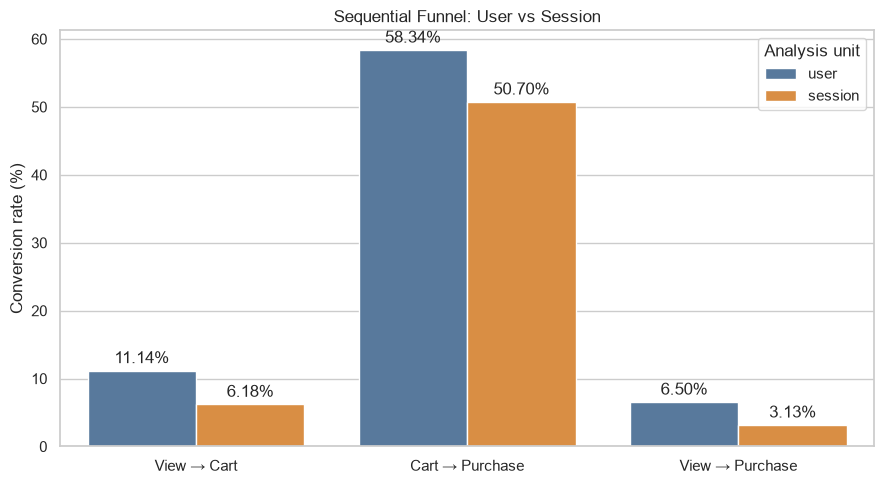

In [20]:
funnel_plot_data = funnel_level_comparison[
    [
        "unit",
        "cart_rate_from_view_pct",
        "purchase_rate_from_cart_pct",
        "purchase_rate_from_view_pct"
    ]
].melt(
    id_vars="unit",
    var_name="metric",
    value_name="rate_pct"
)

metric_labels = {
    "cart_rate_from_view_pct": "View → Cart",
    "purchase_rate_from_cart_pct": "Cart → Purchase",
    "purchase_rate_from_view_pct": "View → Purchase"
}

funnel_plot_data["metric"] = (
    funnel_plot_data["metric"].map(metric_labels)
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=funnel_plot_data,
    x="metric",
    y="rate_pct",
    hue="unit",
    palette=["#4C78A8", "#F28E2B"]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        padding=3
    )

plt.title("Sequential Funnel: User vs Session")
plt.xlabel("")
plt.ylabel("Conversion rate (%)")
plt.legend(title="Analysis unit")
plt.tight_layout()

plt.savefig(
    figure_dir / "sequential_funnel_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

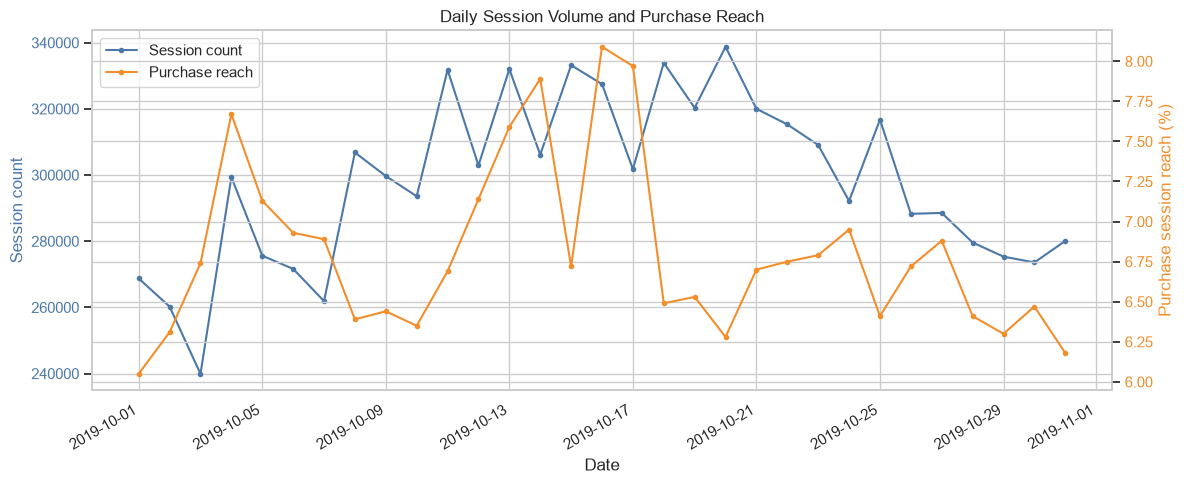

In [22]:
### 每日会话量与购买覆盖率趋势
daily_plot_data = daily_session_metrics.copy()

daily_plot_data["session_date"] = pd.to_datetime(
    daily_plot_data["session_date"]
)

fig, ax1 = plt.subplots(figsize=(12, 5))

# 左轴：每日会话数
ax1.plot(
    daily_plot_data["session_date"],
    daily_plot_data["session_count"],
    color="#4C78A8",
    marker="o",
    markersize=3,
    label="Session count"
)

ax1.set_xlabel("Date")
ax1.set_ylabel(
    "Session count",
    color="#4C78A8"
)
ax1.tick_params(
    axis="y",
    labelcolor="#4C78A8"
)

# 右轴：浏览会话中的购买覆盖率
ax2 = ax1.twinx()

ax2.plot(
    daily_plot_data["session_date"],
    daily_plot_data[
        "purchase_reach_from_view_pct"
    ],
    color="#F28E2B",
    marker="o",
    markersize=3,
    label="Purchase reach"
)

ax2.set_ylabel(
    "Purchase session reach (%)",
    color="#F28E2B"
)
ax2.tick_params(
    axis="y",
    labelcolor="#F28E2B"
)

ax1.set_title(
    "Daily Session Volume and Purchase Reach"
)

# 合并两个坐标轴的图例
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper left"
)

fig.autofmt_xdate()
plt.tight_layout()

fig.savefig(
    figure_dir / "daily_session_purchase_trend.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### 每日趋势结论

每日会话量和购买会话覆盖率并不同步。10 月 20 日附近的会话量达到全月高位，但购买覆盖率相对较低；10 月 16 日的购买覆盖率最高，但其会话量并非全月最高。

这说明流量增长不一定对应购买效率提升，业务监控不能只关注访问规模，还需要同时观察购买表现。由于数据不包含活动、渠道和推荐策略字段，当前结果只能描述日期之间的差异，不能确定波动的具体原因。

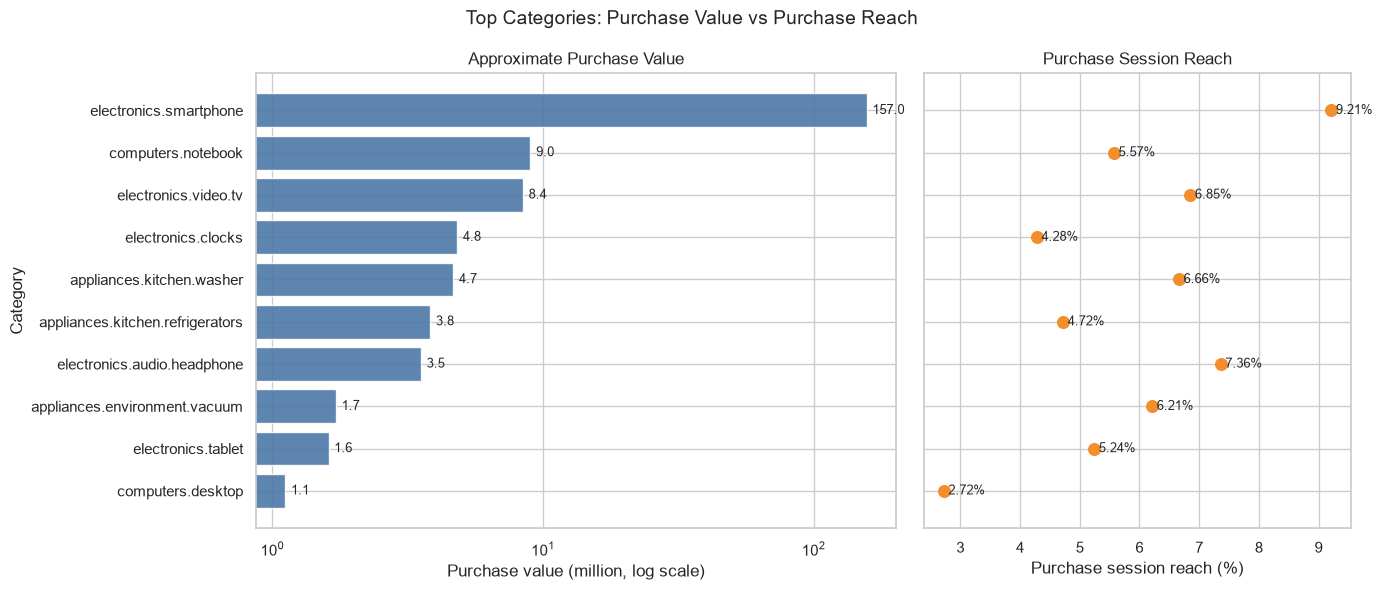

In [24]:
### 核心品类的购买金额与购买覆盖率
top_category_plot = (
    category_metrics
    .sort_values(
        "purchase_value",
        ascending=False
    )
    .head(10)
    .sort_values(
        "purchase_value",
        ascending=True
    )
    .copy()
)

top_category_plot["purchase_value_million"] = (
    top_category_plot["purchase_value"]
    / 1_000_000
)

fig, (ax1, ax2) = plt.subplots(
    1,
    2,
    figsize=(14, 6),
    sharey=True,
    gridspec_kw={
        "width_ratios": [1.5, 1]
    }
)

# 左图：购买金额
bars = ax1.barh(
    top_category_plot["category_code"],
    top_category_plot["purchase_value_million"],
    color="#4C78A8",
    alpha=0.9
)

# 使用对数坐标，减少手机品类对其他柱子的压缩
ax1.set_xscale("log")

ax1.set_title("Approximate Purchase Value")
ax1.set_xlabel("Purchase value (million, log scale)")
ax1.set_ylabel("Category")

for bar, value in zip(
    bars,
    top_category_plot["purchase_value_million"]
):
    ax1.text(
        value * 1.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center",
        fontsize=9
    )

# 右图：购买会话覆盖率
ax2.scatter(
    top_category_plot["purchase_session_reach_pct"],
    top_category_plot["category_code"],
    color="#F28E2B",
    s=70
)

ax2.set_title("Purchase Session Reach")
ax2.set_xlabel("Purchase session reach (%)")
ax2.set_ylabel("")

for rate, category in zip(
    top_category_plot["purchase_session_reach_pct"],
    top_category_plot["category_code"]
):
    ax2.text(
        rate + 0.08,
        category,
        f"{rate:.2f}%",
        va="center",
        fontsize=9
    )

fig.suptitle(
    "Top Categories: Purchase Value vs Purchase Reach",
    fontsize=14
)

plt.tight_layout()

fig.savefig(
    figure_dir / "top_category_value_and_reach.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### 核心品类结论

`electronics.smartphone` 的购买金额近似值约为 1.57 亿，明显高于其他品类，同时购买会话覆盖率达到 9.21%，表现为高规模、高金额和高购买覆盖率的核心品类。

`electronics.audio.headphone` 的购买金额约为 354 万，明显低于手机、笔记本和电视，但购买会话覆盖率达到 7.36%，说明其购买规模较小但相对购买意向较高。

`computers.notebook` 的购买金额约为 898 万，排名第二，但购买会话覆盖率为 5.57%，低于手机、耳机、电视和洗衣机，属于金额贡献较高但仍有购买效率优化空间的品类。

购买金额为购买事件中商品价格的加总近似值。由于数据没有订单 ID 和商品数量字段，该指标不完全等同于真实 GMV。

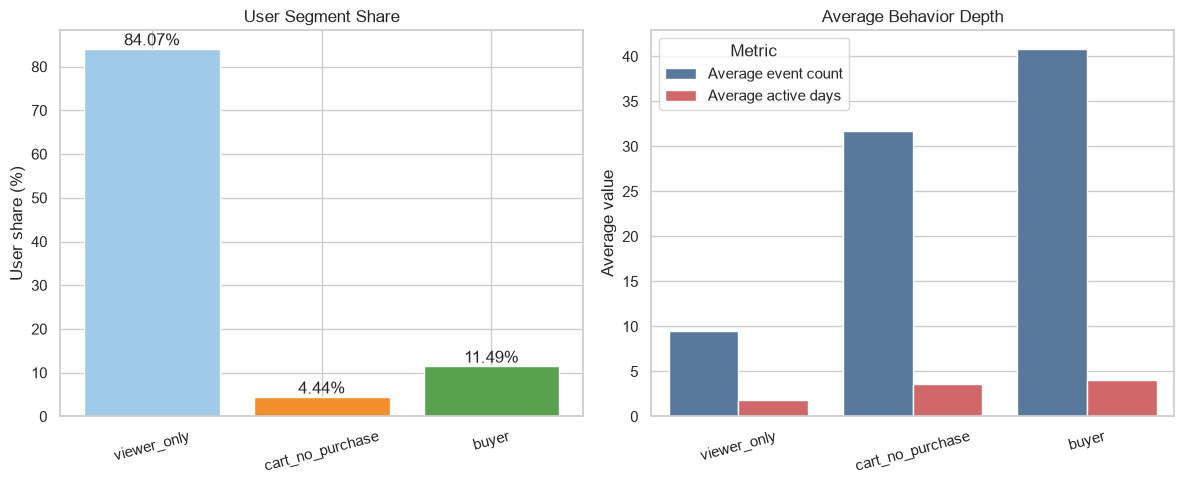

In [28]:
### 用户分层规模与行为深度
segment_plot_data = segment_summary.copy()

segment_order = [
    "viewer_only",
    "cart_no_purchase",
    "buyer"
]

segment_plot_data["user_segment"] = pd.Categorical(
    segment_plot_data["user_segment"],
    categories=segment_order,
    ordered=True
)

segment_plot_data = segment_plot_data.sort_values(
    "user_segment"
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

# 左图：用户占比
bars = axes[0].bar(
    segment_plot_data["user_segment"],
    segment_plot_data["user_share_pct"],
    color=["#A0CBE8", "#F28E2B", "#59A14F"]
)

axes[0].set_title("User Segment Share")
axes[0].set_xlabel("")
axes[0].set_ylabel("User share (%)")

for bar, value in zip(
    bars,
    segment_plot_data["user_share_pct"]
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

# 右图：平均行为数和活跃天数
behavior_plot_data = segment_plot_data[
    [
        "user_segment",
        "avg_event_count",
        "avg_active_days"
    ]
].melt(
    id_vars="user_segment",
    var_name="metric",
    value_name="average_value"
)

metric_name_map = {
    "avg_event_count": "Average event count",
    "avg_active_days": "Average active days"
}

behavior_plot_data["metric"] = (
    behavior_plot_data["metric"]
    .map(metric_name_map)
)

sns.barplot(
    data=behavior_plot_data,
    x="user_segment",
    y="average_value",
    hue="metric",
    ax=axes[1],
    palette={
        "Average event count": "#4C78A8",
        "Average active days": "#E15759"
    }
)

axes[1].set_title("Average Behavior Depth")
axes[1].set_xlabel("")
axes[1].set_ylabel("Average value")
axes[1].legend(title="Metric")


for ax in axes:
    ax.tick_params(
        axis="x",
        rotation=15
    )

plt.tight_layout()

fig.savefig(
    figure_dir / "user_segment_behavior.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### 用户分层结论

只浏览用户占 84.07%，是规模最大的用户群体；买家占 11.49%；加购但未购买用户占 4.44%。

虽然加购未购买用户规模较小，但其平均事件数为 31.71，平均活跃天数为 3.62，明显高于只浏览用户的 9.45 次和 1.81 天，并接近买家的行为深度。

因此，加购未购买用户属于高意向未转化人群，适合作为购物车提醒、个性化推荐或其他转化策略的重点目标用户。但具体策略能否提高购买率，仍需要随机 A/B 实验验证。

In [29]:
expected_figures = [
    "sequential_funnel_comparison.png",
    "daily_session_purchase_trend.png",
    "top_category_value_and_reach.png",
    "user_segment_behavior.png",
]

for filename in expected_figures:
    path = figure_dir / filename

    print(
        filename,
        "存在：" if path.exists() else "缺失：",
        path.exists()
    )

sequential_funnel_comparison.png 存在： True
daily_session_purchase_trend.png 存在： True
top_category_value_and_reach.png 存在： True
user_segment_behavior.png 存在： True
